# MECHA, 9: suberin, lamellae and Casparian bands

**What you will learn:** what the root's barriers are made of, how MECHA describes them at each stage of a root's
life, how a layer of suberin of a given thickness slows the water, and what a Casparian band does when it holds the
solutes back.

**You need:** tutorials 2 (the barriers' codes) and 7 (osmotic potentials). **Run time:** about a minute.

## 1. The barriers in a few words

Water reaching a root's centre crosses rings of cells. Two of them can become **barriers**:

- the **endodermis**, the ring of cells around the central cylinder (the **stele**, which holds the xylem vessels);
- the **exodermis**, a ring under the root's surface (the **epidermis**).

Their cells change as the root ages:

- first a **Casparian band** (or strip): a belt of lignin and suberin inside the walls between two neighbouring
  cells of the ring. Water can no longer slip between the cells along their walls; it must cross a cell's
  **membrane**, the thin film around its content, which lets water through and holds most dissolved substances back;
- then **suberin**: a waxy layer, a **lamella**, laid on the inside of the cells' walls, which slows the water
  crossing the membranes too;
- in some roots, a **tertiary** layer: more wall (cellulose) laid over the lamella, toward the stele.

MECHA codes these stages by one number per root section, its **barrier** code (tutorial 2): 1 a Casparian band in
the endodermis, 2 and 3 the endodermis suberized, 4 to 10 the exodermis' variants, 11 both rings suberized and the
fibres' walls lignified (tutorial 10).

## 2. The barrier codes, impermeable or leaky

By default MECHA's barriers are **impermeable**: a wall with a band or with suberin conducts 10⁻¹⁶ cm² hPa⁻¹ d⁻¹,
nothing. Measured barriers let a little water through. Three parameters give their conductivity (as `kw`, the
conductivity of an ordinary wall, 2.4 × 10⁻⁴ cm² hPa⁻¹ d⁻¹):

| parameter | what it controls | default |
|---|---|---|
| `kw_casparian` | a wall across a Casparian band | 10⁻¹⁶ |
| `kw_suberin_out` | the suberin on a cell's face toward the outside (the cortex) | 10⁻¹⁶ |
| `kw_suberin_in` | the suberin on a cell's face toward the stele | 10⁻¹⁶ |

kr, the section's radial conductivity (tutorial 1), for five codes, first impermeable, then leaky (a band 100 times
less conductive than a wall, suberin 10 000 times):

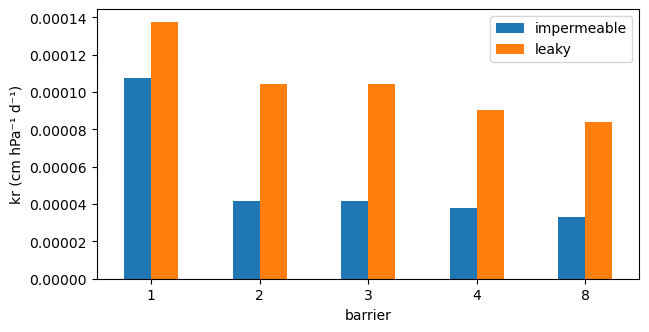

,impermeable,leaky
barrier,,
1,0.000107,0.000137
2,0.000041,0.000104
3,0.000041,0.000104
4,0.000038,0.000090
8,0.000033,0.000084


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.mecha.simulation import simulate

LEAKY = {"kw_casparian": 2.4e-6, "kw_suberin_out": 2.4e-8, "kw_suberin_in": 2.4e-8}
codes = (1, 2, 3, 4, 8)
kr = pd.DataFrame({"impermeable": [simulate(barrier=code).summary["kr"] for code in codes],
                   "leaky": [simulate(LEAKY, barrier=code).summary["kr"] for code in codes]},
                  index=pd.Index(codes, name="barrier"))
kr.plot.bar(rot=0, ylabel="kr (cm hPa⁻¹ d⁻¹)", figsize=(7, 3.5))
plt.show()
kr

- Code 1 (a Casparian band) forces the water through the endodermis' membranes; codes 2 and 3 (suberin) slow it
  there again, and kr falls by more than half when the barriers are impermeable. GRANAP's root has no **passage
  cells** (endodermal cells left without suberin), so 2 and 3 are equal here.
- The exodermis' barriers (4, 8) add a second ring to cross.
- Leaky barriers let part of the water go round the membranes: kr is higher, and the codes differ less.

## 3. Suberin as a layer of its own thickness

By default, MECHA gives suberin as a conductivity of the wall next to the membrane: the lamella has no thickness. With
`suberin_model` 1, each suberized face carries a **lamella** of its own thickness, which the water crosses before
the membrane. Its resistance grows with its thickness, as a thicker sponge lets less water through:

| parameter | what it controls | default |
|---|---|---|
| `suberin_model` | 0 suberin as a conductivity, 1 suberin as a lamella | 0 |
| `secondary_wall_thickness` | the lamella's thickness (µm) | a third of the wall's |
| `tertiary_wall_thickness` | the tertiary layer's thickness behind it, toward the stele (µm) | 0 |
| `primary_wall_thickness` | the wall's own layer between two cells (µm) | the wall's |

A suberized endodermis (code 3), its suberin leaky, the lamella from 0.2 to 2 µm, then a tertiary layer from 0 to
3 µm:

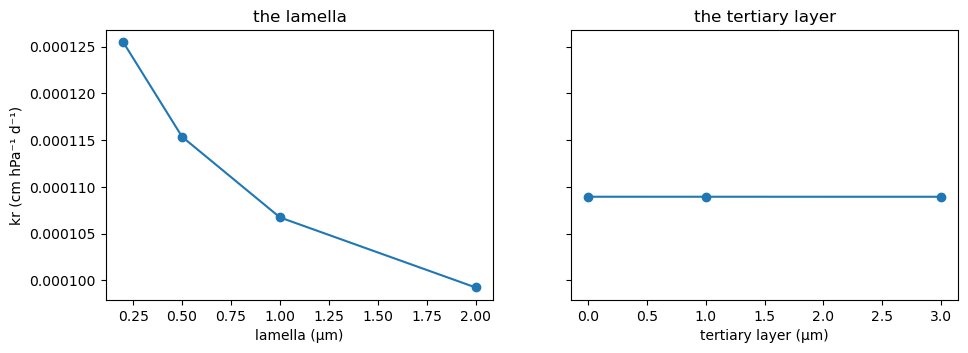

lamella         0.2    0.000125
                0.5    0.000115
                1.0    0.000107
                2.0    0.000099
tertiary layer  0.0    0.000109
                1.0    0.000109
                3.0    0.000109
Name: kr, dtype: float64

In [2]:
lamella = dict(LEAKY, suberin_model=1.)
thicknesses = (0.2, 0.5, 1.0, 2.0)
by_lamella = pd.Series([simulate(dict(lamella, secondary_wall_thickness=value), barrier=3).summary["kr"]
                        for value in thicknesses], index=pd.Index(thicknesses, name="lamella (µm)"), name="kr")
by_tertiary = pd.Series([simulate(dict(lamella, tertiary_wall_thickness=value), barrier=3).summary["kr"]
                         for value in (0., 1., 3.)], index=pd.Index((0., 1., 3.), name="tertiary layer (µm)"),
                        name="kr")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
by_lamella.plot(ax=axes[0], marker="o", ylabel="kr (cm hPa⁻¹ d⁻¹)", title="the lamella")
by_tertiary.plot(ax=axes[1], marker="o", title="the tertiary layer")
plt.show()
pd.concat({"lamella": by_lamella, "tertiary layer": by_tertiary})

- A thicker lamella lowers kr: the water crossing the endodermis' membranes must cross more suberin first (from
  0.2 to 2 µm, kr falls by a fifth).
- The tertiary layer is ordinary wall material: it conducts like a wall, so even 3 µm of it hardly changes kr.

With impermeable suberin (the default 10⁻¹⁶), the lamella's thickness does not matter: nothing crosses it anyway.
The thicknesses count when the suberin's conductivity is measured.

## 4. A Casparian band that holds the solutes back

Tutorial 7 gave the cells and the walls' solutions their **osmotic potentials**: dissolved substances lower the
water's potential, and a membrane, which holds them back, lets that difference draw water across it. How much of
the difference acts is the membrane's **reflection coefficient**, σ: 0 the solutes cross as easily as the water
(no pull), 1 they are all held back (the whole difference pulls).

A Casparian band is a wall impregnated with lignin and suberin: it may hold back solutes too. Its own σ is a
parameter of the osmotic presets:

| parameter | what it controls | default |
|---|---|---|
| `sigma_casparian_endodermis` | the reflection coefficient of the endodermis' Casparian bands, 0 to 1 | 0 |
| `sigma_casparian_exodermis` | the same for the exodermis' bands | 0 |

The osmotic potentials are MECHA's default presets (`os_hetero` 0: the cells at −4800 hPa, the soil's solution at
−500 hPa, the xylem's at −1800 hPa). With a band σ, the difference between the solutions on its two sides draws
water along it. First with the default, **tight** band (10⁻¹⁶), then with a **leaky** band (`kw_casparian` 10 times
below `kw`):

In [3]:
bands = {"tight band": {}, "leaky band": {"kw_casparian": 2.4e-5}}
rows, potentials = [], {}
for name, parameters in bands.items():
    for sigma in (0., 0.5, 1.):
        result = simulate(parameters, barrier=1, osmotic={"os_hetero": 0., "sigma_casparian_endodermis": sigma})
        rows.append({"band": name, "σ": sigma, "kr": result.summary["kr"], "uptake": result.summary["uptake"]})
        potentials[name, sigma] = np.asarray(result.data_structure.get("standard_psi"), dtype=float).copy()
uptake = pd.DataFrame(rows)
uptake.pivot(index="σ", columns="band", values="uptake")

band,leaky band,tight band
σ,,
0.0,0.006685,0.0034
0.5,0.007120,0.0034
1.0,0.007554,0.0034


- With the **leaky** band, σ raises the water uptake: the solutions inside the endodermis are more concentrated than
  the soil's, so the band, holding their solutes back, draws water inward along it (+13 % at σ 1).
- With the **tight** band, σ changes nothing measurable: hardly any water flows along a wall of 10⁻¹⁶, whatever
  pulls it. σ then only changes the **water potentials of the band's walls** themselves, which the pull sets but
  which pass nothing on:

In [4]:
tight = abs(potentials["tight band", 1.] - potentials["tight band", 0.])
leaky = abs(potentials["leaky band", 1.] - potentials["leaky band", 0.])
pd.DataFrame({"nodes changed by more than 1 hPa": [(tight > 1.).sum(), (leaky > 1.).sum()],
              "largest change (hPa)": [tight.max(), leaky.max()]}, index=["tight band", "leaky band"])

,nodes changed by more than 1 hPa,largest change (hPa)
tight band,32,20.502119
leaky band,7106,465.415699


The tight band's σ moves only a few dozen nodes (the bands' walls and their junctions), by about 20 hPa; the leaky band's moves the whole section's potentials, because its water flows.

## 5. In short

| what | effect on kr and the uptake |
|---|---|
| a barrier code with impermeable barriers | the rings' membranes are the only way: kr falls with each ring |
| leaky barriers | part of the water goes round: kr rises, the codes differ less |
| the lamella's thickness (`suberin_model` 1) | thicker, kr falls, only when the suberin conducts |
| the tertiary layer | ordinary wall: little effect |
| a band's σ | draws water along a leaky band; on a tight band, only its walls' potentials move |

The equations behind these rules (the wall's layers side by side, the lamella in series with the membrane, the band's
σ in the flow) are in the developer tutorial 11 and in `doc/equations.rst`.

## Try it yourself

1. With the leaky values, at which barrier code is kr the lowest? Make the exodermis' suberin leakier than the
   endodermis' (`kw_suberin_exodermis`).
2. With `kw_suberin_in` and `kw_suberin_out` at 2.4 × 10⁻⁹, how much does the lamella's thickness still change kr
   at code 3? Why?
3. Give the exodermis' band a σ (`sigma_casparian_exodermis`, code 8, `kw_casparian` 2.4 × 10⁻⁵): does the uptake
   rise as much as with the endodermis'?

**Next:** `10_scaling_one_tissue.ipynb`.